In [2]:
import pandas as pd 

data = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

data.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


**Repérage des variables.** La liste des colonnes permet d’identifier la cible `Churn`, les informations clients et les caractéristiques des abonnements avant de choisir les traitements.

In [3]:
data.columns.tolist()

['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

**Identification des clients.** `customerID` devient l’index : cet identifiant sert à retrouver les lignes, mais ne doit pas être considéré comme une caractéristique prédictive du comportement de résiliation.

In [4]:
data.set_index('customerID', inplace = True)
data.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
customerID,,,,,,,,,,,,,,,,,,,,
7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


**Premier diagnostic.** `describe()` résume les variables numériques ; `info()` indique les types et le nombre de valeurs non nulles. L’objectif est de repérer les incohérences de format et les données manquantes avant l’analyse.

In [5]:

data.describe()

data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7043 entries, 7590-VHVEG to 3186-AJIEK
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null 

**Recherche des montants vides.** On compte les lignes où `TotalCharges` contient un espace plutôt qu’un montant. Ces chaînes empêchent une utilisation numérique directe de cette variable.

In [6]:
(data["TotalCharges"]==" ").sum()




np.int64(11)

**Préparation des valeurs manquantes.** Les espaces dans `TotalCharges` sont remplacés par une chaîne de caractères `pd.NA`. Attention : avec les guillemets, il ne s’agit pas de la véritable valeur manquante pandas ; la conversion numérique suivante les transformera néanmoins en `NaN` grâce à `errors="coerce"`.

In [7]:
data["TotalCharges"] = data["TotalCharges"].replace(' ', 'pd.NA')


**Conversion en numérique.** `pd.to_numeric(..., errors="coerce")` transforme les montants valides en nombres et les valeurs non convertibles en `NaN`. `info()` permet ensuite de vérifier le nouveau type.

In [8]:
data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors='coerce')

data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7043 entries, 7590-VHVEG to 3186-AJIEK
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null 

**Traitement des lignes incomplètes.** Les observations dont `TotalCharges` est manquant sont supprimées pour conserver une variable exploitable. Ce choix simplifie la suite, mais réduit légèrement le nombre de clients étudiés.

In [9]:
data.dropna(subset="TotalCharges", axis=0 , inplace = True)

data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7032 entries, 7590-VHVEG to 3186-AJIEK
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7032 non-null   object 
 1   SeniorCitizen     7032 non-null   int64  
 2   Partner           7032 non-null   object 
 3   Dependents        7032 non-null   object 
 4   tenure            7032 non-null   int64  
 5   PhoneService      7032 non-null   object 
 6   MultipleLines     7032 non-null   object 
 7   InternetService   7032 non-null   object 
 8   OnlineSecurity    7032 non-null   object 
 9   OnlineBackup      7032 non-null   object 
 10  DeviceProtection  7032 non-null   object 
 11  TechSupport       7032 non-null   object 
 12  StreamingTV       7032 non-null   object 
 13  StreamingMovies   7032 non-null   object 
 14  Contract          7032 non-null   object 
 15  PaperlessBilling  7032 non-null   object 
 16  PaymentMethod     7032 non-null 

**Vérification des valeurs manquantes.** On compte les `NaN` restants dans chaque colonne afin de s’assurer que le nettoyage est suffisant pour les analyses et les modèles.

In [10]:
data.isnull().sum()

gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

**Contrôle des identifiants.** On recherche les doublons dans l’index `customerID`. Des identifiants répétés pourraient fausser l’interprétation du nombre de clients.

In [11]:
data.index.duplicated().sum()


np.int64(0)

On convertit Churn en No=0 et Yes=1

**Encodage de la cible.** On transforme `Churn` en variable binaire : `0` signifie que le client reste, `1` qu’il résilie. 

In [12]:
data["Churn"] = data["Churn"].str.strip().map({"No" : 0 , "Yes" : 1})


In [13]:
data.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
customerID,,,,,,,,,,,,,,,,,,,,
7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


**Description des variables catégorielles.** On examine le nombre de valeurs distinctes et les modalités les plus fréquentes. Cela aide à comprendre la composition de la clientèle et à préparer l’encodage.

In [14]:
data.describe(include = "object")

,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod
count,7032,7032,7032,7032,7032,7032,7032,7032,7032,7032,7032,7032,7032,7032,7032
unique,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4
top,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check
freq,3549,3639,4933,6352,3385,3096,3497,3087,3094,3472,2809,2781,3875,4168,2365


**Mesure du déséquilibre des classes.** Les proportions de `Churn=0` et `Churn=1` indiquent si les résiliations sont minoritaires. Cette information est essentielle : une accuracy élevée peut masquer une mauvaise détection des clients qui partent.

In [15]:
data['Churn'].value_counts(normalize=True) * 100

Churn
0    73.421502
1    26.578498
Name: proportion, dtype: float64

Il  faudra donc équilibré notre jeu de donnée lorsqu'on voudra entraîner notre model.

**Inventaire avant visualisation.** On réaffiche les noms des colonnes pour sélectionner les caractéristiques à explorer et éviter les erreurs de nommage.

In [16]:
data.columns.tolist()

['gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

**Exploration des caractéristiques catégorielles.** Pour chaque variable choisie, un diagramme compare les effectifs des clients qui restent et de ceux qui résilient. Cela permet de repérer des associations possibles avec `Churn`, sans établir de causalité. Comme les effectifs des groupes diffèrent, les pourcentages de résiliation par modalité seraient utiles en complément.

<function matplotlib.pyplot.show(close=None, block=None)>

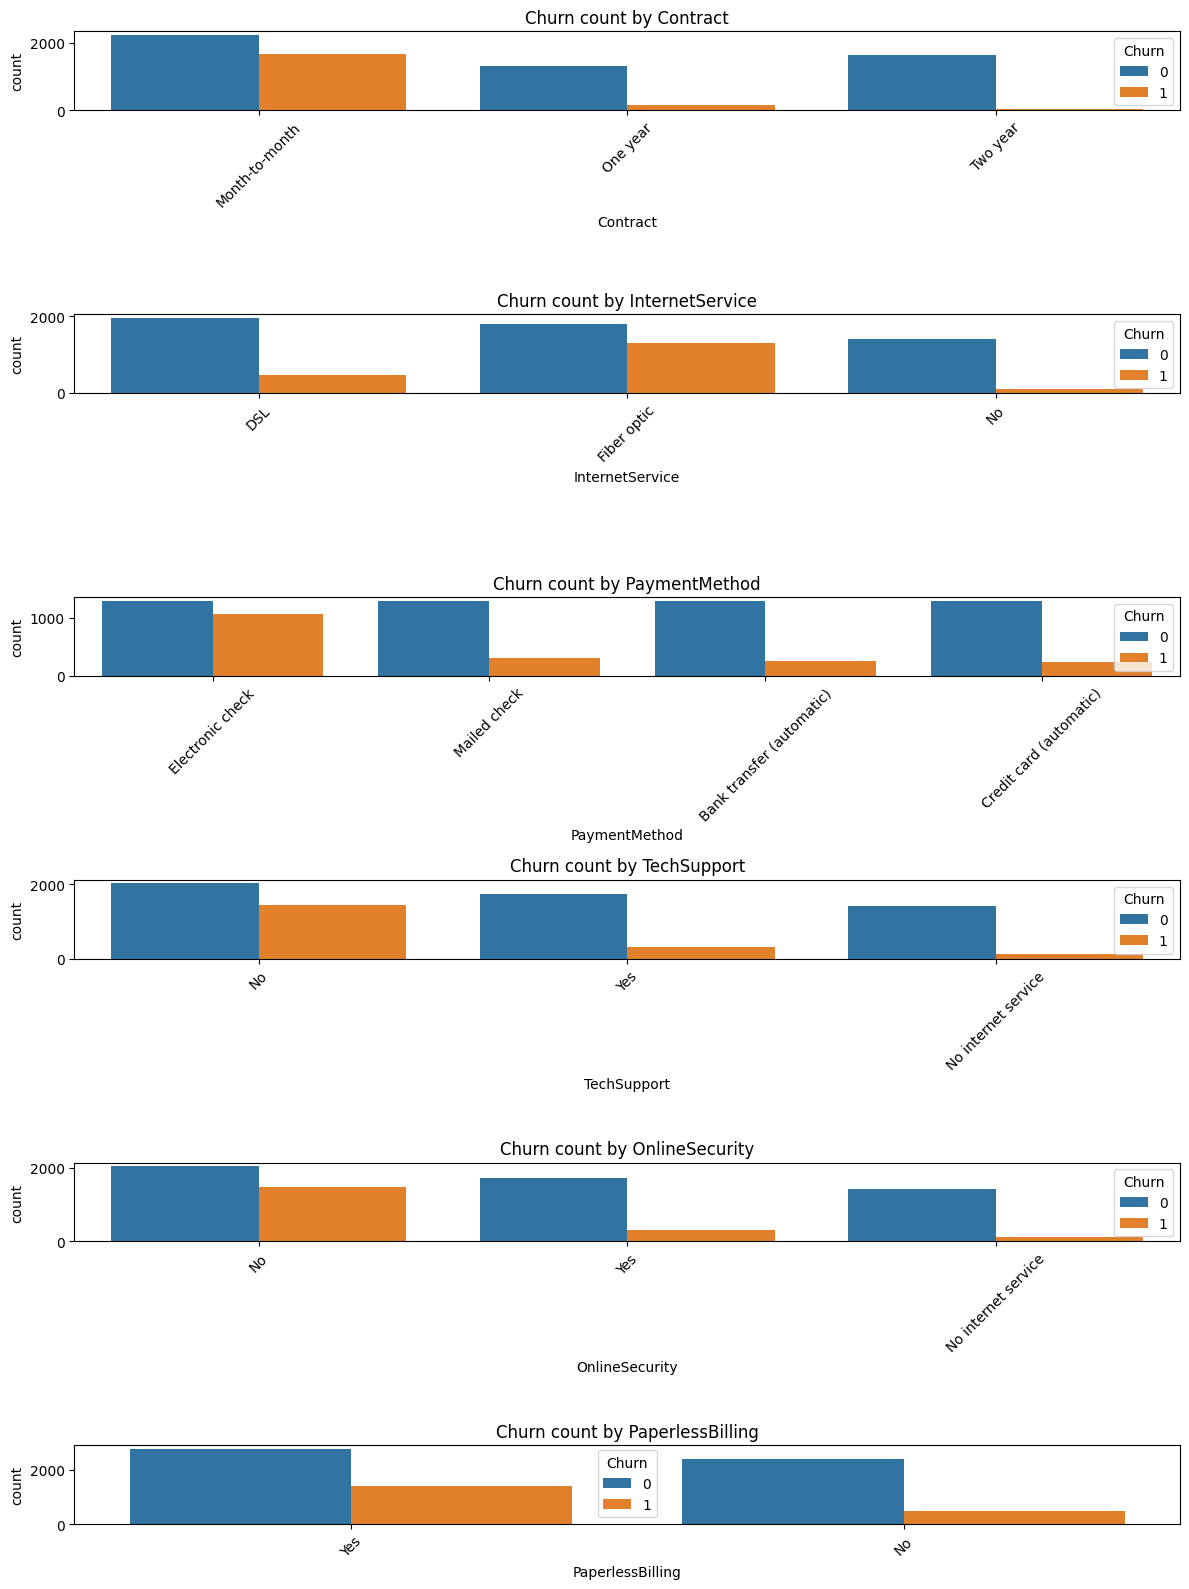

In [17]:
import seaborn as sn
import matplotlib.pyplot as plt

plt.figure(figsize=(12,16))

useful_cat_features= [

'Contract', "InternetService", "PaymentMethod", "TechSupport" , "OnlineSecurity","PaperlessBilling"
]

for i,col in enumerate(useful_cat_features,1): 
    plt.subplot(len(useful_cat_features), 1, i)
    sn.countplot(data=data , x=col , hue="Churn")
    plt.title(f'Churn count by {col}')
    plt.xticks(rotation=45)
    plt.tight_layout()

plt.show



**Exploration des variables quantitatives.** Les boxplots comparent la distribution de l’ancienneté (`tenure`) et des charges selon `Churn`. Ils aident à observer des différences de médiane, de dispersion et des valeurs extrêmes, sans prouver un lien causal.

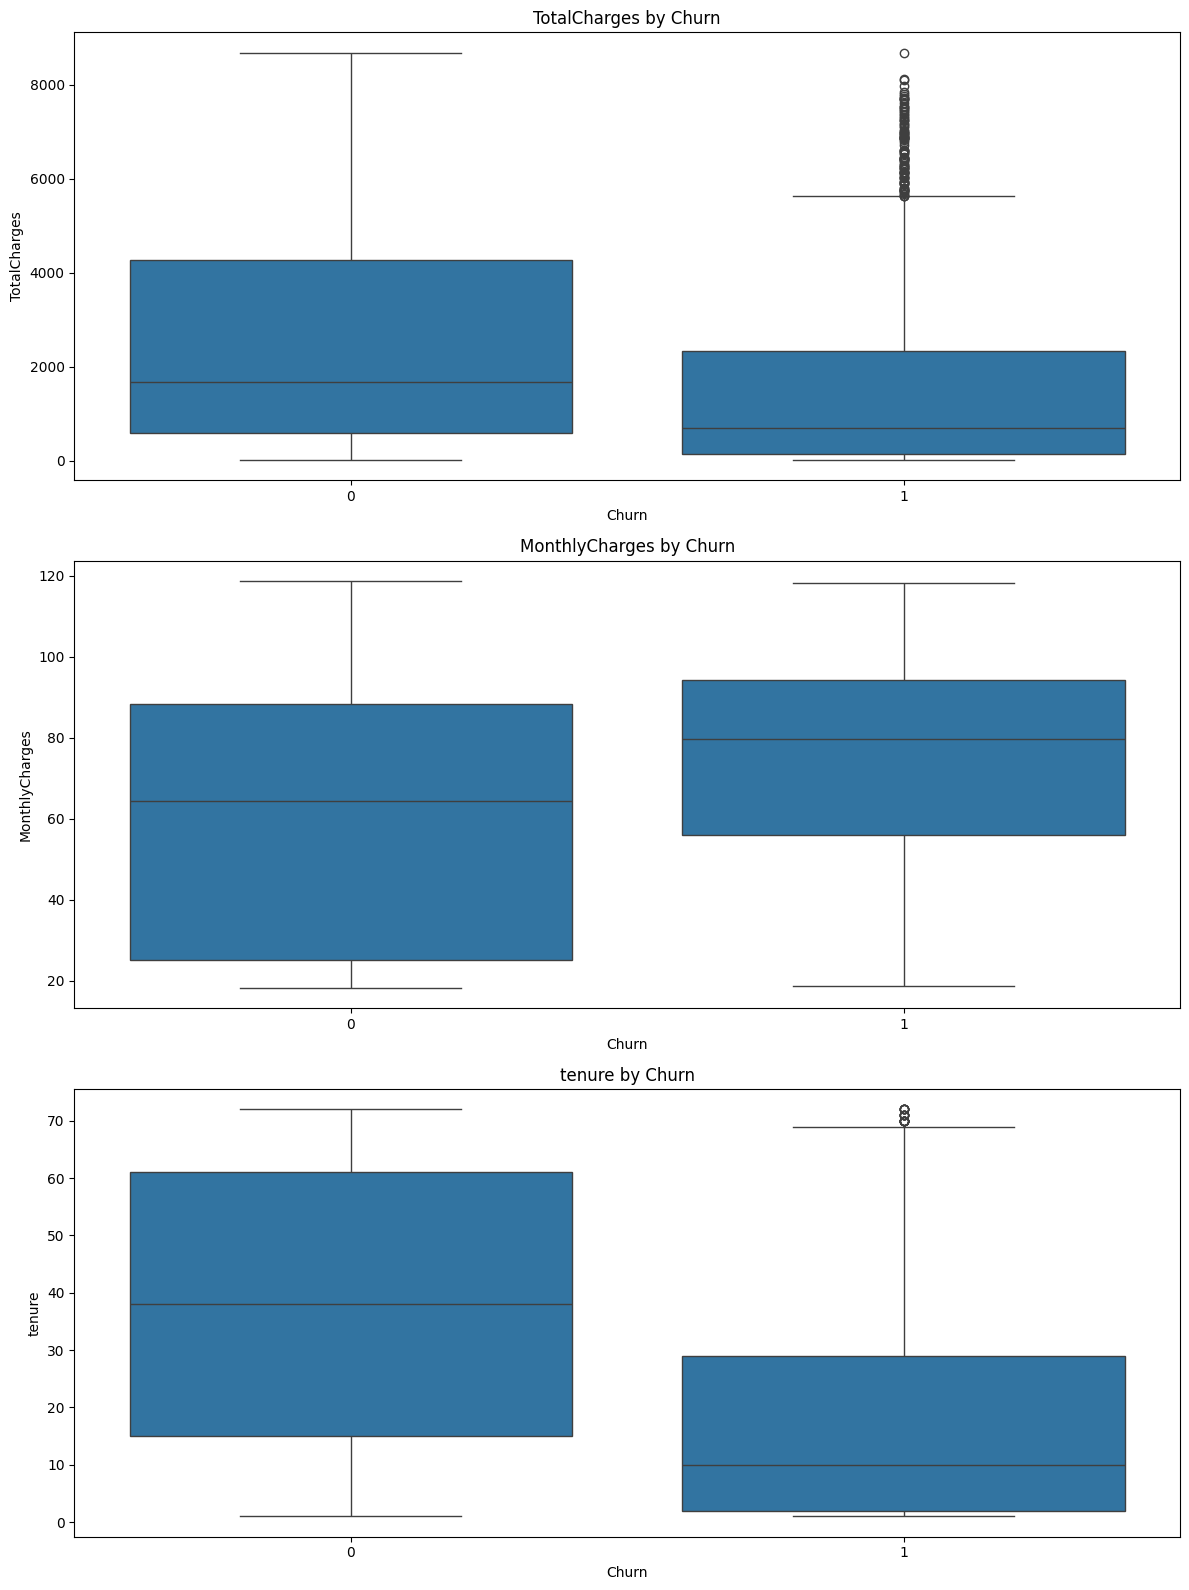

In [18]:



num_features = [
    'TotalCharges', 'MonthlyCharges', 'tenure'
]

plt.figure(figsize=(12, 16))

for i, col in enumerate(num_features, 1):
    plt.subplot(len(num_features), 1, i)
    sn.boxplot(data=data, x="Churn", y=col)
    plt.title(f'{col} by Churn')
    plt.tight_layout()

plt.show()


Ces trois graphiques mettent en évidence plusieurs tendances :
- TotalCharges : les clients fidèles ont généralement des dépenses cumulées plus importantes.
- MonthlyCharges : les clients qui résilient ont tendance à payer des mensualités plus élevées.
- tenure : les clients qui résilient ont généralement une ancienneté beaucoup plus faible.
Ces observations suggèrent que l'ancienneté et le montant des mensualités sont deux variables potentiellement importantes pour la prédiction du churn.

**Analyse des corrélations linéaires.** La matrice de corrélation des variables numériques fournit une première vue des relations entre montants, ancienneté et résiliation. Une corrélation faible n’implique pas nécessairement qu’une variable est inutile pour un modèle non linéaire.

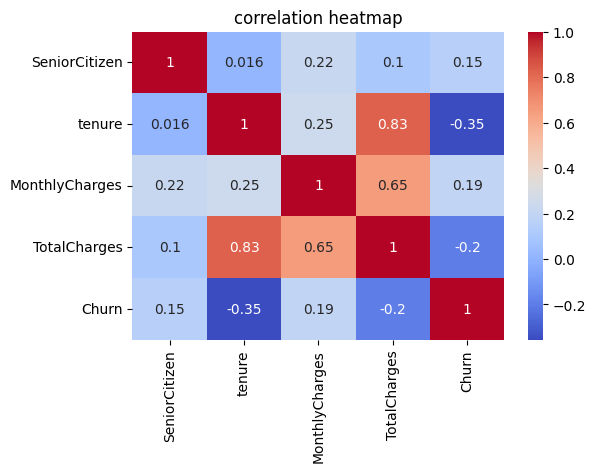

In [19]:
data_numeric = data.select_dtypes(include=["number"])

corr = data_numeric.corr()

plt.figure(figsize=(6, 4))
sn.heatmap(corr, annot=True , cmap='coolwarm')
plt.title("correlation heatmap")
plt.show()

`tenure` est la variable numérique la plus corrélée au churn, suivie de TotalCharges et MonthlyCharges

**Sélection des variables numériques.** Cette liste conserve les trois grandeurs quantitatives que l’on souhaite suivre : ancienneté, facture mensuelle et total facturé. Elle sert de repère pour les étapes suivantes.

In [20]:
val_num = ["tenure", "MonthlyCharges","TotalCharges"]



**Séparation des types de variables.** Les colonnes textuelles sont identifiées comme catégorielles et les colonnes numériques sont regroupées à part, en excluant `Churn` qui est la cible. Cette distinction prépare le choix d’encodages adaptés.

In [21]:
categorical_cols = [ cname for cname in data.columns  if
                    data[cname].dtype == "object"    ]


numerical_cols = [cname for cname in data.columns if 
                data[cname].dtype in ['int64', 'float64']]

numerical_cols.remove("Churn")

print(categorical_cols)
print(numerical_cols)

['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


**Choix de l’encodage.** Les variables catégorielles sont réparties entre celles à deux modalités et celles à plus de deux modalités. Cette distinction évite d’attribuer artificiellement un ordre numérique à des catégories multiples.

In [22]:
binary_features = [col for col in categorical_cols if data[col].nunique() ==2 ]

print( binary_features)

multy_features = [col for col in categorical_cols if data[col].nunique() > 2]

print(multy_features)


['gender', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling']
['MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaymentMethod']


**Encodage des variables binaires.** `LabelEncoder` remplace les deux modalités de chaque colonne par `0` et `1`.

In [23]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
for col in binary_features:
    data[col]= le.fit_transform(data[col])

data.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
customerID,,,,,,,,,,,,,,,,,,,,
7590-VHVEG,0,0,1,0,1,0,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,1,Electronic check,29.85,29.85,0
5575-GNVDE,1,0,0,0,34,1,No,DSL,Yes,No,Yes,No,No,No,One year,0,Mailed check,56.95,1889.50,0
3668-QPYBK,1,0,0,0,2,1,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,1,Mailed check,53.85,108.15,1
7795-CFOCW,1,0,0,0,45,0,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,0,Bank transfer (automatic),42.30,1840.75,0
9237-HQITU,0,0,0,0,2,1,No,Fiber optic,No,No,No,No,No,No,Month-to-month,1,Electronic check,70.70,151.65,1


**Encodage des variables à plusieurs modalités.** `get_dummies` crée des colonnes indicatrices pour chaque catégorie. On évite ainsi de donner une hiérarchie arbitraire à des modalités comme les moyens de paiement.

In [24]:


data = pd.get_dummies(data, columns=multy_features)



**Contrôle des variables encodées.** L’affichage permet de vérifier que les colonnes catégorielles ont été remplacées par des indicateurs utilisables par les algorithmes.

In [25]:
data.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
customerID,,,,,,,,,,,,,,,,,,,,,
7590-VHVEG,0,0,1,0,1,0,1,29.85,29.85,0,...,True,False,False,True,False,False,False,False,True,False
5575-GNVDE,1,0,0,0,34,1,0,56.95,1889.50,0,...,True,False,False,False,True,False,False,False,False,True
3668-QPYBK,1,0,0,0,2,1,1,53.85,108.15,1,...,True,False,False,True,False,False,False,False,False,True
7795-CFOCW,1,0,0,0,45,0,0,42.30,1840.75,0,...,True,False,False,False,True,False,True,False,False,False
9237-HQITU,0,0,0,0,2,1,1,70.70,151.65,1,...,True,False,False,True,False,False,False,False,True,False


**Découpage indépendant.** On réserve dès maintenant 20 % des données au test final. Les 80 % restants sont divisés en entraînement (60 % du total) et validation (20 %). La validation sert à comparer les modèles et choisir le seuil ; le test reste inutilisé jusque-là.

In [26]:
from sklearn.model_selection import train_test_split
X = data.drop(columns='Churn')
y = data['Churn']
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
X_train, X_valid, y_train, y_valid = train_test_split(X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=42)
print('Entraînement :', X_train.shape, 'Validation :', X_valid.shape, 'Test :', X_test.shape)

Entraînement : (4218, 40) Validation : (1407, 40) Test : (1407, 40)


**Comptage des classes.** On vérifie le nombre de clients dans chaque catégorie de `Churn` afin de motiver l’étape de rééquilibrage qui suit comme expliqué précédemment.

In [27]:
data["Churn"].value_counts()

Churn
0    5163
1    1869
Name: count, dtype: int64

**Rééquilibrage (SMOTE).** Pour les expériences simples, SMOTE est appliqué exclusivement au jeu d’entraînement. Pour la validation croisée et la recherche d’hyperparamètres, il doit impérativement être inclus **dans une pipeline `imblearn`**, afin d’être réappliqué seulement au sous-ensemble d’entraînement de chaque fold. Avec des indicateurs one-hot, SMOTE classique peut créer des valeurs intermédiaires.

In [28]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train,y_train)

**Premier modèle de référence : Random Forest.** Une forêt de 100 arbres est entraînée sur les données d’entraînement rééquilibrées puis évaluée sur la validation. L’accuracy est complétée par le rappel, la précision et la matrice de confusion pour la classe `Churn=1`.

In [29]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

model = RandomForestClassifier(n_estimators=100, random_state=0)
model.fit(X_train_resampled, y_train_resampled)
preds = model.predict(X_valid)
print('Accuracy :', accuracy_score(y_valid, preds))
print(classification_report(y_valid, preds))
print(confusion_matrix(y_valid, preds))

Accuracy : 0.7768301350390903
              precision    recall  f1-score   support

           0       0.83      0.88      0.85      1033
           1       0.59      0.50      0.54       374

    accuracy                           0.78      1407
   macro avg       0.71      0.69      0.70      1407
weighted avg       0.77      0.78      0.77      1407

[[905 128]
 [186 188]]


Le modèle présente une performance globale correcte, mais il identifie beaucoup mieux les clients fidèles que ceux qui résilient.

Le principal problème concerne les 186 faux négatifs, car ces clients risquent de quitter l'entreprise sans être identifiés à temps.

L'objectif étant de prédire le churn, il serait pertinent de chercher à améliorer le rappel (recall) de la classe 1, quitte à accepter davantage de faux positifs, afin de détecter une plus grande proportion des clients susceptibles de résilier.

Testons quand même d'autres models possibles : 

**Comparaison de plusieurs familles de modèles.** Random Forest, Extra Trees, gradient boosting et SVM sont entraînés sur les mêmes données puis évalués sur la même validation. Cette comparaison aide à déterminer si une autre méthode détecte mieux les résiliations. Le SVM utilise une standardisation car il est sensible à l’échelle des variables. Les métriques par classe comptent autant que l’accuracy globale.

In [30]:
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
modeles = {
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=0),
    'Extra Trees': ExtraTreesClassifier(n_estimators=300, random_state=0),
    'HistGradientBoosting': HistGradientBoostingClassifier(random_state=0),
    'SVC RBF': Pipeline([('scaler', StandardScaler()), ('model', SVC(kernel='rbf'))]),
}
for nom, modele in modeles.items():
    modele.fit(X_train_resampled, y_train_resampled)
    preds_modele = modele.predict(X_valid)
    print(f'\n=== {nom} ===')
    print('Accuracy :', accuracy_score(y_valid, preds_modele))
    print(classification_report(y_valid, preds_modele))
    print(confusion_matrix(y_valid, preds_modele))


=== Random Forest ===
Accuracy : 0.7768301350390903
              precision    recall  f1-score   support

           0       0.83      0.88      0.85      1033
           1       0.59      0.50      0.54       374

    accuracy                           0.78      1407
   macro avg       0.71      0.69      0.70      1407
weighted avg       0.77      0.78      0.77      1407

[[905 128]
 [186 188]]

=== Extra Trees ===
Accuracy : 0.7583511016346838
              precision    recall  f1-score   support

           0       0.82      0.86      0.84      1033
           1       0.55      0.48      0.51       374

    accuracy                           0.76      1407
   macro avg       0.69      0.67      0.68      1407
weighted avg       0.75      0.76      0.75      1407

[[888 145]
 [195 179]]

=== HistGradientBoosting ===
Accuracy : 0.7889125799573561
              precision    recall  f1-score   support

           0       0.84      0.88      0.86      1033
           1       0.62    

Bien que HistGradientBoosting obtienne des performances légèrement supérieures, RandomForestClassifier reste un choix pertinent avec une accuracy de 77,68 %.

Ce modèle présente l'avantage d'être facilement interprétable grâce à l'analyse de l'importance des variables, permettant d'identifier les facteurs qui contribuent le plus à la prédiction du churn.

Ainsi, nous choisissons de conserver RandomForestClassifier pour son bon compromis entre performances prédictives, robustesse et interprétabilité, tout en reconnaissant que HistGradientBoosting obtient de meilleurs résultats sur les métriques évaluées.

On peut éssayer de voir si supprimer certaines DATA permettent d'améliorer notre model.

Pour ça on s'interesse à la correlation des variables qu'on avait déjà étudié en avant, SeniorCitizen semble être un premier choix, on peut aussi s'interesser aux variables catégoriques : 

**Retour sur les variables disponibles.** `info()` sert à revoir les colonnes et leurs types avant d’examiner lesquelles pourraient être retirées du modèle.

In [31]:

data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7032 entries, 7590-VHVEG to 3186-AJIEK
Data columns (total 41 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   gender                                   7032 non-null   int64  
 1   SeniorCitizen                            7032 non-null   int64  
 2   Partner                                  7032 non-null   int64  
 3   Dependents                               7032 non-null   int64  
 4   tenure                                   7032 non-null   int64  
 5   PhoneService                             7032 non-null   int64  
 6   PaperlessBilling                         7032 non-null   int64  
 7   MonthlyCharges                           7032 non-null   float64
 8   TotalCharges                             7032 non-null   float64
 9   Churn                                    7032 non-null   int64  
 10  MultipleLines_No                      

**Classement des associations avec la cible.** On calcule la corrélation de chaque colonne numérique avec `Churn` et on trie les résultats pour identifier les associations linéaires les plus marquées. Cette mesure est exploratoire : elle ne suffit pas, à elle seule, à décider de supprimer une variable.

In [32]:

# Calculer la corrélation de toutes les variables avec Churn
correlations = data.corr(numeric_only=True)["Churn"]

# Exclure Churn de ses propres corrélations
correlations = correlations.drop("Churn")

# Trier les corrélations par ordre décroissant de valeur absolue
correlations = correlations.loc[
    correlations.abs().sort_values(ascending=False).index
]

print(correlations)


Contract_Month-to-month                    0.404565
tenure                                    -0.354049
OnlineSecurity_No                          0.342235
TechSupport_No                             0.336877
InternetService_Fiber optic                0.307463
Contract_Two year                         -0.301552
PaymentMethod_Electronic check             0.301455
OnlineBackup_No                            0.267595
DeviceProtection_No                        0.252056
OnlineSecurity_No internet service        -0.227578
TechSupport_No internet service           -0.227578
StreamingTV_No internet service           -0.227578
InternetService_No                        -0.227578
OnlineBackup_No internet service          -0.227578
DeviceProtection_No internet service      -0.227578
StreamingMovies_No internet service       -0.227578
TotalCharges                              -0.199484
MonthlyCharges                             0.192858
PaperlessBilling                           0.191454
Contract_One

**Focus sur les indicateurs binaires.** On isole les colonnes qui ne prennent que deux valeurs pour visualiser leur corrélation avec la résiliation. Le but est de présélectionner des variables à tester, pas de conclure immédiatement à leur inutilité.

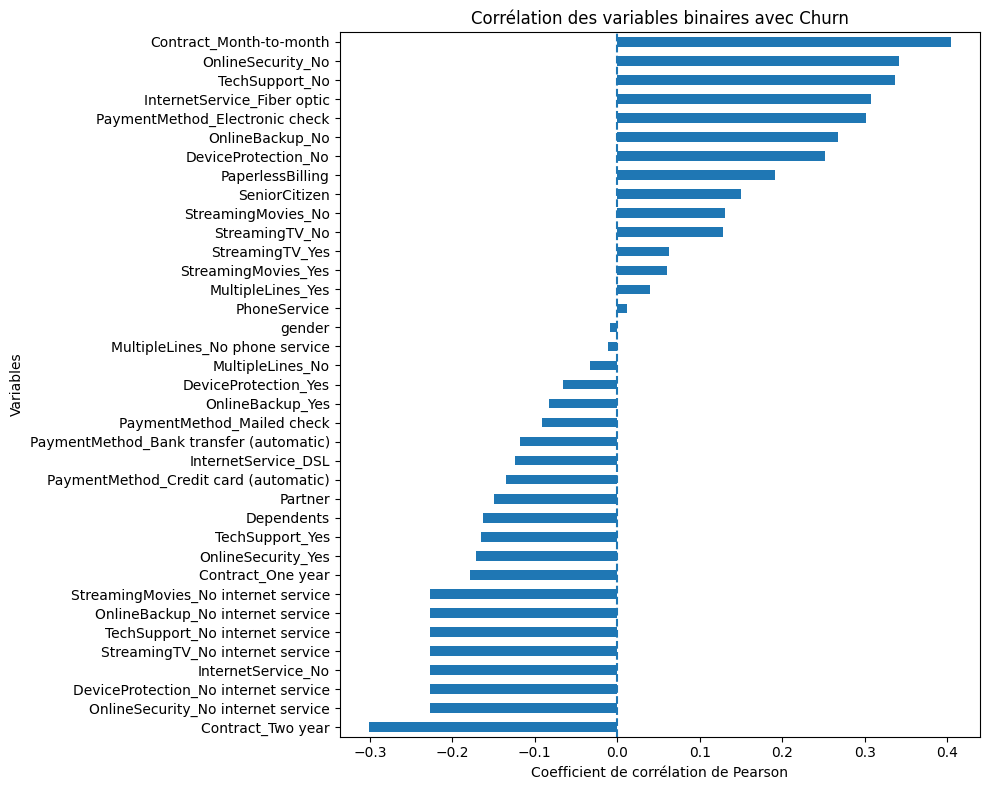

In [33]:
import matplotlib.pyplot as plt

# Calculer les corrélations des variables binaires
correlations = data.corr(numeric_only=True)["Churn"].drop("Churn")

binary_cols = [
    col for col in correlations.index
    if data[col].nunique() == 2
]

correlations_binary = correlations[binary_cols]
correlations_binary = correlations_binary.sort_values()

# Afficher le graphique
plt.figure(figsize=(10, 8))
correlations_binary.plot(kind="barh")

plt.title("Corrélation des variables binaires avec Churn")
plt.xlabel("Coefficient de corrélation de Pearson")
plt.ylabel("Variables")
plt.axvline(x=0, linestyle="--")
plt.tight_layout()
plt.show()

Les variables interessantes sont : gender,PhoneService , MultipleLines, StreamingMovies_Yes , StreamingTV_Yes , DeviceProtection_Yes , OnlineBackup_Yes

**Essais de suppression de variables.** Plusieurs scénarios sont comparés à un modèle de référence en retirant certaines colonnes des données d’entraînement et de validation. On mesure l’évolution de l’accuracy pour voir si une représentation plus simple peut être aussi performante. Attention : `accuracy_initiale` dépend ici de l’objet `model` laissé par les cellules précédentes ; ce n’est pas nécessairement une Random Forest identique aux modèles testés. De plus, sélectionner des variables sur le même jeu de validation risque de suradapter les choix à ce jeu.

In [34]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
variables_a_supprimer = [
    ['gender'],
    ['PhoneService', 'MultipleLines_No', 'MultipleLines_Yes', 'MultipleLines_No phone service'],
    ['StreamingMovies_Yes'], ['StreamingTV_Yes'], ['DeviceProtection_Yes'],
    ['OnlineBackup_Yes'], ['SeniorCitizen']
]
def score_suppression(colonnes):
    X_tr = X_train_resampled.drop(columns=colonnes, errors='ignore')
    X_va = X_valid.drop(columns=colonnes, errors='ignore')
    rf = RandomForestClassifier(n_estimators=100, random_state=0)
    rf.fit(X_tr, y_train_resampled)
    return accuracy_score(y_valid, rf.predict(X_va))
accuracy_initiale = score_suppression([])
meilleur_score = {'Aucune suppression': accuracy_initiale}
print('Accuracy initiale :', round(accuracy_initiale, 4))
for colonnes in variables_a_supprimer:
    score = score_suppression(colonnes)
    meilleur_score[tuple(colonnes)] = score
    print(f'Sans {colonnes} : {score:.4f} ({(score-accuracy_initiale)*100:+.2f} points)')
print('Meilleur scénario exploratoire :', max(meilleur_score, key=meilleur_score.get))

Accuracy initiale : 0.7768
Sans ['gender'] : 0.7775 (+0.07 points)
Sans ['PhoneService', 'MultipleLines_No', 'MultipleLines_Yes', 'MultipleLines_No phone service'] : 0.7797 (+0.28 points)
Sans ['StreamingMovies_Yes'] : 0.7783 (+0.14 points)
Sans ['StreamingTV_Yes'] : 0.7726 (-0.43 points)
Sans ['DeviceProtection_Yes'] : 0.7804 (+0.36 points)
Sans ['OnlineBackup_Yes'] : 0.7747 (-0.21 points)
Sans ['SeniorCitizen'] : 0.7726 (-0.43 points)
Meilleur scénario exploratoire : ('DeviceProtection_Yes',)


essayons maintenant plusieurs combinaisons de gender, DeviceProtection_Yes et StreamingMovies_Yes qui semble être les variables les plus interessantes à supprimer : 

**Essai des combinaisons de suppressions.** Les trois indicateurs présélectionnés sont retirés seuls ou par groupes afin d’observer si leurs effets se cumulent. Le classement est exploratoire : `accuracy_initiale` est calculée à partir de `preds` hérité de la cellule précédente, et `model` est également réutilisé. La comparaison avec un modèle initial explicitement réentraîné serait plus fiable.

In [35]:
from itertools import combinations
variables_candidates = ['gender', 'DeviceProtection_Yes', 'StreamingMovies_Yes']
resultats = {'Aucune suppression': score_suppression([])}
for n_suppressions in range(1, len(variables_candidates) + 1):
    for combinaison in combinations(variables_candidates, n_suppressions):
        resultats[combinaison] = score_suppression(list(combinaison))
for scenario, score in sorted(resultats.items(), key=lambda kv: kv[1], reverse=True):
    print(f'{scenario} : {score:.4f}')
print('Meilleur scénario exploratoire :', max(resultats, key=resultats.get))

('DeviceProtection_Yes',) : 0.7804
('StreamingMovies_Yes',) : 0.7783
('gender', 'StreamingMovies_Yes') : 0.7783
('gender',) : 0.7775
Aucune suppression : 0.7768
('gender', 'DeviceProtection_Yes') : 0.7768
('DeviceProtection_Yes', 'StreamingMovies_Yes') : 0.7768
('gender', 'DeviceProtection_Yes', 'StreamingMovies_Yes') : 0.7761
Meilleur scénario exploratoire : ('DeviceProtection_Yes',)


Supprimer des données ne semble pas améliorer grandement notre model.

**Contrôle méthodologique.** Les expériences précédentes explorent des variables sur la validation. La validation croisée qui suit utilise uniquement le jeu d’entraînement original, et place SMOTE dans chaque fold. Le jeu de test demeure totalement isolé.

In [36]:
# La vérification croisée est effectuée dans les cellules suivantes.
# Aucun rééchantillonnage global ne doit être utilisé pour ces scores.

Il faut maintenant vérifier la pertinance de ce changement avec une validation croisée : 

**Validation croisée en 5 folds.** On évalue le modèle sans `OnlineBackup_Yes` sur les données originales d’entraînement, en plaçant SMOTE à l’intérieur de chaque fold pour éviter la fuite d’information.

In [37]:
import numpy as np
from sklearn.model_selection import StratifiedKFold, cross_val_score
from imblearn.pipeline import Pipeline as ImbPipeline
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
def pipeline_rf():
    return ImbPipeline([
        ('smote', SMOTE(random_state=42)),
        ('rf', RandomForestClassifier(n_estimators=100, random_state=0))
    ])
X_train_reduit = X_train.drop(columns=['OnlineBackup_Yes'], errors='ignore')
scores = cross_val_score(pipeline_rf(), X_train_reduit, y_train, cv=cv, scoring='accuracy', n_jobs=-1)
print('Scores par fold :', scores)
print(f'Accuracy moyenne : {scores.mean():.4f} ± {scores.std():.4f}')

Scores par fold : [0.79739336 0.78672986 0.78672986 0.78766311 0.78410439]
Accuracy moyenne : 0.7885 ± 0.0046


**Comparaison croisée à conditions identiques.** Le modèle complet et le modèle réduit sont évalués sur les mêmes folds. SMOTE est ajusté uniquement dans chaque fold d’entraînement.

In [38]:
scores_initial = cross_val_score(pipeline_rf(), X_train, y_train, cv=cv, scoring='accuracy', n_jobs=-1)
scores_reduit = cross_val_score(pipeline_rf(), X_train_reduit, y_train, cv=cv, scoring='accuracy', n_jobs=-1)
print(f'Modèle complet : {scores_initial.mean():.4f} ± {scores_initial.std():.4f}')
print(f'Sans OnlineBackup_Yes : {scores_reduit.mean():.4f} ± {scores_reduit.std():.4f}')
difference = scores_reduit.mean() - scores_initial.mean()
print(f'Différence : {difference*100:+.2f} points')
if difference > 0:
    print('Le modèle réduit a le meilleur score CV moyen.')
else:
    print('Le modèle complet est au moins aussi bon en CV.')

Modèle complet : 0.7888 ± 0.0043
Sans OnlineBackup_Yes : 0.7885 ± 0.0046
Différence : -0.02 points
Le modèle complet est au moins aussi bon en CV.


On optimise les hyperparamètres maintenant : 

**Recherche d’hyperparamètres.** `RandomizedSearchCV` explore 50 configurations d’une Random Forest. SMOTE est intégré à la pipeline afin de ne pas contaminer les folds de validation. Le jeu de test final n’est pas consulté.

In [39]:
from sklearn.model_selection import RandomizedSearchCV
param_grid = {
    'rf__n_estimators': [100, 200, 300],
    'rf__max_depth': [None, 10, 20, 30],
    'rf__min_samples_split': [2, 5, 10],
    'rf__min_samples_leaf': [1, 2, 4],
    'rf__max_features': ['sqrt', 'log2'],
    'rf__bootstrap': [True, False],
}
random_search = RandomizedSearchCV(
    estimator=pipeline_rf(), param_distributions=param_grid,
    n_iter=50, cv=cv, scoring='accuracy', n_jobs=-1,
    random_state=42, verbose=1
)
random_search.fit(X_train, y_train)
model_rf_final = random_search.best_estimator_
print('Meilleurs hyperparamètres :', random_search.best_params_)
print('Meilleur score CV :', random_search.best_score_)
print('Accuracy sur validation :', model_rf_final.score(X_valid, y_valid))

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Meilleurs hyperparamètres : {'rf__n_estimators': 100, 'rf__min_samples_split': 10, 'rf__min_samples_leaf': 4, 'rf__max_features': 'sqrt', 'rf__max_depth': 10, 'rf__bootstrap': True}
Meilleur score CV : 0.7975353201441477
Accuracy sur validation : 0.7839374555792467


Les meilleurs hyperparamètres sont affichés par `random_search.best_params_` après exécution. Ils peuvent changer avec le nouveau découpage et la correction de la validation croisée : il ne faut pas réutiliser automatiquement ceux des anciennes expériences.

**Conclusion intermédiaire — Random Forest.** Les modèles ont été comparés sur un même jeu de validation. La sélection de variables a été vérifiée par validation croisée et l’optimisation a été réalisée avec SMOTE à l’intérieur de chaque fold. Essayons maintenant une nouvelle approche.

# Réseau de Neurone

**Préparation du réseau de neurones.** On conserve la structure initiale (64 puis 32 neurones, BatchNormalization, Dropout). Pour éviter toute fuite, les variables numériques sont standardisées avec un scaler ajusté **uniquement sur l’entraînement** ; les colonnes binaires restent inchangées.

In [40]:
# Préparation des jeux pour le réseau, sans changer le découpage précédent.
from sklearn.preprocessing import StandardScaler
X_train_neurone = X_train.copy().astype(float)
X_valid_neurone = X_valid.copy().astype(float)
X_test_neurone = X_test.copy().astype(float)
colonnes_numeriques_neurone = [c for c in ['tenure', 'MonthlyCharges', 'TotalCharges'] if c in X_train_neurone]
scaler_neurone = StandardScaler()
X_train_neurone[colonnes_numeriques_neurone] = scaler_neurone.fit_transform(X_train_neurone[colonnes_numeriques_neurone])
X_valid_neurone[colonnes_numeriques_neurone] = scaler_neurone.transform(X_valid_neurone[colonnes_numeriques_neurone])
X_test_neurone[colonnes_numeriques_neurone] = scaler_neurone.transform(X_test_neurone[colonnes_numeriques_neurone])
y_train_neurone, y_valid_neurone, y_test_neurone = y_train, y_valid, y_test

**Dimension d’entrée.** La taille de l’entrée correspond au nombre de variables de `X_train_neurone`, préparé dans la cellule précédente.

In [41]:
from tensorflow import keras
from tensorflow.keras import layers
input_shape = (X_train_neurone.shape[1],)
print('Dimension des entrées :', input_shape)

Dimension des entrées : (40,)


**Entraînement du réseau.** Le modèle conserve les couches denses de l’expérience initiale. L’arrêt anticipé surveille la perte de validation. Le seuil est choisi ensuite sur la validation, puis appliqué une seule fois au jeu de test indépendant. L'utilisation de `Layers.Dropout()` permet d'éviter des généralisations lié à des patterns présent dans notre jeu de donnée.

2026-10-21 21:10:43.058436: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Epoch 1/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - binary_accuracy: 0.4953 - loss: 1.0336 - val_binary_accuracy: 0.5174 - val_loss: 0.6900
Epoch 2/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - binary_accuracy: 0.5624 - loss: 0.8834 - val_binary_accuracy: 0.6389 - val_loss: 0.6650
Epoch 3/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - binary_accuracy: 0.5996 - loss: 0.7865 - val_binary_accuracy: 0.6823 - val_loss: 0.6470
Epoch 4/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - binary_accuracy: 0.6354 - loss: 0.7422 - val_binary_accuracy: 0.7122 - val_loss: 0.6328
Epoch 5/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - binary_accuracy: 0.6529 - loss: 0.7010 - val_binary_accuracy: 0.7342 - val_loss: 0.6191
Epoch 6/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - binary_accuracy: 0.6705 - loss: 0.6674 - val_binary_accuracy: 0.7498 - val_loss: 0.6039
Epoch 7/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - binary_accuracy: 0.6849 - loss: 0.6451 - val_binary_accuracy: 0.7562 - val_loss: 0.5905
Epoch 8/200
9/9 ━━━━

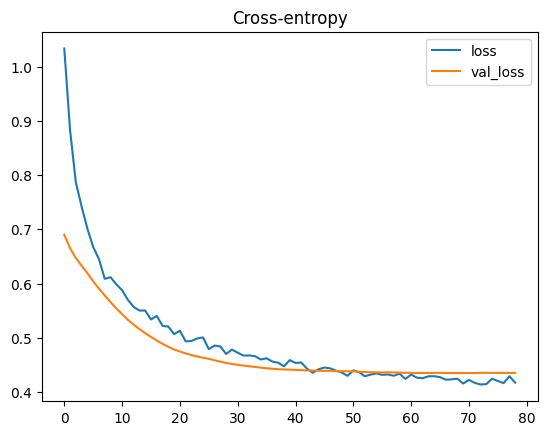

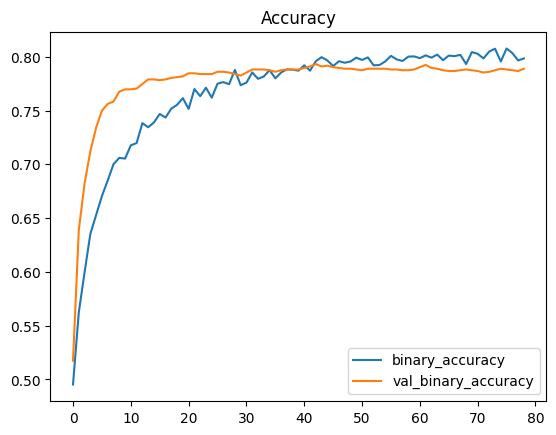

In [42]:
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd
import matplotlib.pyplot as plt
keras.utils.set_random_seed(42)
model_neurone = keras.Sequential([
    layers.Input(shape=input_shape),
    layers.BatchNormalization(),
    layers.Dense(64, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(32, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(1, activation='sigmoid')
])
model_neurone.compile(optimizer='adam', loss='binary_crossentropy', metrics=['binary_accuracy'])
early_stopping = keras.callbacks.EarlyStopping(monitor='val_loss', patience=20, min_delta=0.001, restore_best_weights=True)
history_neurone = model_neurone.fit(
    X_train_neurone, y_train_neurone,
    validation_data=(X_valid_neurone, y_valid_neurone),
    batch_size=512, epochs=200, callbacks=[early_stopping], verbose=1
)
y_proba_neurone = model_neurone.predict(X_valid_neurone, verbose=0).ravel()
preds_neurone = (y_proba_neurone >= 0.5).astype(int)
print(classification_report(y_valid_neurone, preds_neurone, zero_division=0))
print(confusion_matrix(y_valid_neurone, preds_neurone))
history_df_neurone = pd.DataFrame(history_neurone.history)
history_df_neurone[['loss', 'val_loss']].plot(title='Cross-entropy')
history_df_neurone[['binary_accuracy', 'val_binary_accuracy']].plot(title='Accuracy')
plt.show()

Le réseau de neurones présente un apprentissage stable et des performances satisfaisantes, avec une accuracy de validation proche de 79 % et sans surapprentissage notable.

Cependant, pour évaluer réellement son efficacité dans la prédiction du churn, il faudra également analyser la précision, le recall et le F1-score de la classe 1, afin de vérifier sa capacité à détecter les clients susceptibles de résilier.

Le seuil de 0,5 n’est pas forcément le plus adapté pour détecter les clients qui résilient. On compare plusieurs seuils **sur la validation seulement**. Pour une action de fidélisation ciblée, on privilégie ici la précision de `Churn=1` parmi les seuils testés (avec le rappel affiché pour mesurer le compromis).

**Choix du seuil et évaluation finale.** La précision de la classe `Churn=1` est mesurée pour chaque seuil sur la validation. Une fois le seuil choisi, on évalue le réseau et la Random Forest sur le **jeu de test indépendant**, sans réajuster les modèles ni modifier le seuil après avoir vu les résultats.

In [43]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score
liste_seuil = [0.5, 0.4, 0.35, 0.3, 0.25]
resultats_seuils = []
for seuil in liste_seuil:
    preds_seuil = (y_proba_neurone >= seuil).astype(int)
    precision = precision_score(y_valid_neurone, preds_seuil, zero_division=0)
    rappel = recall_score(y_valid_neurone, preds_seuil, zero_division=0)
    resultats_seuils.append((seuil, precision, rappel))
    print(f'\nSeuil {seuil} — précision Churn=1 : {precision:.3f}, rappel : {rappel:.3f}')
    print(classification_report(y_valid_neurone, preds_seuil, zero_division=0))
    print(confusion_matrix(y_valid_neurone, preds_seuil))
# Priorité à la précision ; à égalité, conserver le meilleur rappel.
seuil_optimal_neurone, _, _ = max(resultats_seuils, key=lambda x: (x[1], x[2]))
print('\nSeuil retenu sur validation :', seuil_optimal_neurone)

# Évaluation finale : test jamais utilisé pour l'entraînement ou la sélection du seuil.
print('\n=== RANDOM FOREST : TEST FINAL ===')
preds_rf_test = model_rf_final.predict(X_test)
print(classification_report(y_test, preds_rf_test, zero_division=0))
print(confusion_matrix(y_test, preds_rf_test))
print('\n=== RÉSEAU DE NEURONES : TEST FINAL ===')
y_proba_test_neurone = model_neurone.predict(X_test_neurone, verbose=0).ravel()
preds_test_neurone = (y_proba_test_neurone >= seuil_optimal_neurone).astype(int)
print(classification_report(y_test_neurone, preds_test_neurone, zero_division=0))
print(confusion_matrix(y_test_neurone, preds_test_neurone))


Seuil 0.5 — précision Churn=1 : 0.615, rappel : 0.535
              precision    recall  f1-score   support

           0       0.84      0.88      0.86      1033
           1       0.62      0.53      0.57       374

    accuracy                           0.79      1407
   macro avg       0.73      0.71      0.72      1407
weighted avg       0.78      0.79      0.78      1407

[[908 125]
 [174 200]]

Seuil 0.4 — précision Churn=1 : 0.574, rappel : 0.631
              precision    recall  f1-score   support

           0       0.86      0.83      0.85      1033
           1       0.57      0.63      0.60       374

    accuracy                           0.78      1407
   macro avg       0.72      0.73      0.72      1407
weighted avg       0.79      0.78      0.78      1407

[[858 175]
 [138 236]]

Seuil 0.35 — précision Churn=1 : 0.557, rappel : 0.666
              precision    recall  f1-score   support

           0       0.87      0.81      0.84      1033
           1       0.56  

**Conclusion et limites.** Le seuil optimal dépend de l’objectif métier : un seuil faible améliore souvent le rappel au prix de fausses alertes supplémentaires, tandis qu’un seuil élevé privilégie la précision. Le seuil retenu ci-dessus est choisi uniquement sur la validation, puis évalué sur un test indépendant. Les résultats définitifs sont ceux affichés à l’exécution, et non les chiffres des anciens essais. Les scores de test ne doivent plus servir à retoucher le modèle. **Limites :** le déséquilibre des classes complique la détection des résiliations ; SMOTE classique sur des variables one-hot peut produire des valeurs synthétiques non binaires. Pour aller plus loin, on pourrait comparer une stratégie `class_weight` et utiliser une métrique adaptée à l’objectif métier.

Les différents modèles testés obtiennent des performances relativement proches, mais le réseau de neurones présente le meilleur compromis global, avec une accuracy de 79,53 %, une précision de 62 % et un F1-score de 0,61 pour la classe 1.

Cependant, le Random Forest final reste plus efficace pour détecter les clients qui résilient, avec un rappel de 64 % contre 59 % pour le réseau de neurones.

L'étude des différents seuils montre également qu'une diminution du seuil de décision permet d'améliorer le rappel, mais entraîne davantage de faux positifs.

Choix final : nous retenons le réseau de neurones comme meilleur modèle global. Néanmoins, si l'objectif prioritaire de l'entreprise est de détecter un maximum de clients susceptibles de résilier, le Random Forest final peut être privilégié grâce à son meilleur rappel.